# Notebook A: dữ liệu, làm sạch, SQL và hình RQ1

**Đề tài:** Chọn vị trí đeo cảm biến cho nhận dạng hoạt động bằng lời giải thích được kiểm chứng qua huấn luyện lại trên MHEALTH với mười mô hình

**Sinh viên A** chạy lần lượt từ trên xuống. Mỗi ô code có một ô hướng dẫn ngay phía trên gồm ba ý: làm gì, vì sao, kiểm tra gì. Sản phẩm bàn giao cho Notebook B là file parquet trong `data/processed/`, file `sql/queries.sql` và `data/processed/manifest.json`.

## Bước 0. Môi trường

- **Làm gì:** cài thư viện (một lần), tạo thư mục, nạp ba hàm tiện ích.
- **Vì sao:** mọi notebook của nhóm dùng chung cấu trúc thư mục để bàn giao file cho nhau.
- **Kiểm tra:** ô chạy xong không báo lỗi.
- **Lưu ý:** sau khi `%pip install` xong phải **Restart kernel** rồi mới chạy tiếp. Nếu cài hoặc nâng cấp pyarrow khi kernel đang chạy, ô lưu parquet ở Bước 2 sẽ báo `ArrowKeyError: No type extension with name arrow.py_extension_type found`, kéo theo lỗi `SQL is not defined` và `Table har does not exist` ở các ô sau.

In [1]:
# run once per machine, then comment out and RESTART THE KERNEL before running the next cells
# %pip install -r requirements.txt

In [2]:
import os, glob, zipfile, urllib.request
for d in ['data/raw', 'data/processed', 'report', 'sql']: os.makedirs(d, exist_ok=True)
def fetch(url, name):                                   # download once into data/raw
    path = 'data/raw/' + name
    if not os.path.exists(path): print('downloading', url); urllib.request.urlretrieve(url, path)
    return path
def unzip_all(folder='data/raw'):                       # unpack archives, including archives inside archives
    done = set()
    while True:
        todo = [z for z in glob.glob(folder + '/**/*.zip', recursive=True) if z not in done]
        if not todo: break
        for z in todo:
            with zipfile.ZipFile(z) as f: f.extractall(os.path.dirname(z))
            done.add(z)
def find1(name):                                        # locate one file wherever the archive put it
    hits = glob.glob('data/raw/**/' + name, recursive=True); assert hits, 'not found: ' + name; return hits[0]

## Bước 1a. Tải dữ liệu

- **Làm gì:** tải file gốc về `data/raw/` và giải nén. Ô này bỏ qua nếu dữ liệu đã có.
- **Vì sao:** người khác chạy lại notebook phải nhận đúng cùng một bộ dữ liệu.
- **Kiểm tra:** dòng cuối in số file tìm thấy. Nếu tải tự động lỗi, tải tay tại `archive.ics.uci.edu/dataset/319`, chép vào `data/raw/` rồi chạy lại ô này.

In [3]:
FILES = [('https://archive.ics.uci.edu/static/public/319/mhealth+dataset.zip', 'mhealth.zip')]
MARKER = 'data/raw/**/mHealth_subject*.log'
if not glob.glob(MARKER, recursive=True):
    for url, name in FILES: fetch(url, name)
    unzip_all()
found = glob.glob(MARKER, recursive=True)
assert found, 'data not found: download by hand from archive.ics.uci.edu/dataset/319 into data/raw and run this cell again'
print(len(found), 'files found, for example', found[0])

10 files found, for example data/raw\MHEALTHDATASET\mHealth_subject1.log


## Bước 1b. Nạp dữ liệu và trích đặc trưng

- **Làm gì:** đọc file gốc, tạo bảng làm việc.
- **Vì sao:** mọi bước sau dùng bảng này, nên số dòng và số cột in ra ở đây là con số ghi vào mục Data của bài.
- **Kiểm tra:** so số người, số lớp, số dòng với mô tả của bộ dữ liệu.

In [4]:
# Step 1b: MHEALTH (Banos et al., 2014): 10 people, 12 activities, sensors on chest, left ankle and right wrist, 50 Hz
# download (72 MB, no account): https://archive.ics.uci.edu/static/public/319/mhealth+dataset.zip
import pandas as pd, numpy as np, glob, os
from numpy.lib.stride_tricks import sliding_window_view
cols = (['chest_acc_' + a for a in 'xyz'] + ['ecg_lead1', 'ecg_lead2'] +
        [p + '_' + s + '_' + a for p in ['ankle', 'wrist'] for s in ['acc', 'gyro', 'mag'] for a in 'xyz'] + ['label'])   # 24 columns
keep = [c for c in cols if c != 'label' and '_mag_' not in c]          # magnetometer depends on the room, left out
WIN, STEP = 100, 10                                    # 2 s windows, 0.2 s step at 50 Hz
rows, log = [], []
for f in sorted(glob.glob('data/raw/**/mHealth_subject*.log', recursive=True)):
    d = pd.read_csv(f, sep='\t', header=None, names=cols)
    sid = int(os.path.basename(f).split('subject')[1].split('.')[0]); n0 = len(d)
    d['run'] = (d.label != d.label.shift()).cumsum()    # a window never crosses a change of activity
    d = d[d.label != 0].dropna(); log.append([sid, n0, len(d)])        # label 0 is the null class
    for (lab, run), g in d.groupby(['label', 'run']):
        if len(g) < WIN: continue
        x = sliding_window_view(g[keep].to_numpy(), WIN, axis=0)[::STEP]       # shape (n, 17, 100)
        out = {'subject': sid, 'label': lab, 'run': run, 'win': np.arange(len(x))}
        for j, c in enumerate(keep):
            out[c + '_mean'] = x[:, j].mean(1); out[c + '_std'] = x[:, j].std(1)
        for p in ['chest', 'ankle', 'wrist']:           # acceleration magnitude per body position
            i = keep.index(p + '_acc_x'); m = np.sqrt((x[:, i:i + 3] ** 2).sum(1))
            out[p + '_accmag_mean'] = m.mean(1); out[p + '_accmag_std'] = m.std(1)
        rows.append(pd.DataFrame(out))
df = pd.concat(rows, ignore_index=True)
print(df.shape, df.subject.nunique(), 'people', df.label.nunique(), 'activities')

(33148, 44) 10 people 12 activities


## Bước 2. Làm sạch có nhật ký

- **Làm gì:** loại dòng lỗi, đặt tên nhãn, lưu parquet và nhật ký làm sạch.
- **Vì sao:** phản biện sẽ hỏi vì sao số dòng khác tài liệu gốc; nhật ký là câu trả lời.
- **Kiểm tra:** mở `report/table_cleaning_log.csv`, mỗi dòng bị bỏ phải có lý do.

In [5]:
# Step 2: activity names, cleaning log per person, window-level table
names = {1: 'standing', 2: 'sitting', 3: 'lying', 4: 'walking', 5: 'stairs', 6: 'waist_bend', 7: 'arm_raise',
         8: 'knee_bend', 9: 'cycling', 10: 'jogging', 11: 'running', 12: 'jumping'}
df['activity'] = df.label.map(names)
clog = pd.DataFrame(log, columns=['subject', 'raw_rows', 'labelled_rows']).sort_values('subject', ignore_index=True)
clog['null_class_pct'] = (100 * (1 - clog.labelled_rows / clog.raw_rows)).round(1)      # most of each log is unlabelled
clog.to_csv('report/table_cleaning_log.csv', index=False); print(clog)
df = df.dropna().drop_duplicates(['subject', 'run', 'win'])
df.to_parquet('data/processed/mhealth.parquet', index=False)
print(df.shape); print(df.activity.value_counts())

   subject  raw_rows  labelled_rows  null_class_pct
0        1    161280          35174            78.2
1        2    130561          35532            72.8
2        3    122112          35380            71.0
3        4    116736          35328            69.7
4        5    119808          33947            71.7
5        6     98304          32205            67.2
6        7    104448          34253            67.2
7        8    129024          33332            74.2
8        9    135168          34354            74.6
9       10     98304          33690            65.7
(33148, 45)
activity
standing      2980
sitting       2980
lying         2980
walking       2980
cycling       2980
jogging       2980
running       2980
stairs        2924
arm_raise     2848
knee_bend     2839
waist_bend    2737
jumping        940
Name: count, dtype: int64


## Bước 3. SQL trả lời RQ1 và tạo bảng mô hình

- **Làm gì:** ghi các truy vấn vào `sql/queries.sql` rồi chạy từng truy vấn bằng DuckDB. Kết quả truy vấn Qn lưu ở `report/table_qn.csv` (Q4 là lệnh tạo bảng nên không có file).
- **Vì sao:** RQ1 được trả lời bằng bảng số; đặc trưng xu hướng dùng LAG nên chỉ lấy thông tin quá khứ, không rò rỉ (không dùng LEAD vì LEAD lấy cửa sổ tương lai).
- **Lưu ý khi viết bài:** `ecg_spread` là độ lệch chuẩn của điện áp ECG thô trong cửa sổ, không phải nhịp tim. Giá trị tăng ở jogging và running nên được mô tả là biến động tín hiệu ECG (có thể do nhiễu chuyển động), không viết là "nhịp tim thay đổi".
- **Kiểm tra:** tính tay một nhóm nhỏ và so với kết quả truy vấn.

In [6]:
SQL = r"""-- Step 3: sql/queries.sql
CREATE OR REPLACE TABLE har AS SELECT * FROM 'data/processed/mhealth.parquet';
-- Q1: windows per person and activity (balance of the protocol)
SELECT subject, COUNT(*) AS n, COUNT(DISTINCT activity) AS activities FROM har GROUP BY 1 ORDER BY 1;
-- Q2: which body position moves in which activity, and how the heart signal changes
SELECT activity, COUNT(*) AS n, AVG(chest_accmag_std) AS chest_motion, AVG(ankle_accmag_std) AS ankle_motion,
       AVG(wrist_accmag_std) AS wrist_motion, AVG(ecg_lead1_std) AS ecg_spread
FROM har GROUP BY 1 HAVING COUNT(*) > 100 ORDER BY ankle_motion;
-- Q3: spread between people inside one activity for each body position (the source of person shift), cv = sd / mean
WITH s AS (SELECT activity, subject, AVG(chest_accmag_std) AS chest, AVG(ankle_accmag_std) AS ankle,
                  AVG(wrist_accmag_std) AS wrist FROM har GROUP BY 1, 2)
SELECT activity, AVG(chest) AS chest_mean, STDDEV(chest) / AVG(chest) AS chest_cv, AVG(ankle) AS ankle_mean,
       STDDEV(ankle) / AVG(ankle) AS ankle_cv, AVG(wrist) AS wrist_mean, STDDEV(wrist) / AVG(wrist) AS wrist_cv
FROM s GROUP BY 1 ORDER BY wrist_cv DESC;
-- Q4: model table; the motion trend uses only earlier windows of the same run (LAG, no leakage)
CREATE OR REPLACE TABLE feat AS
SELECT * EXCLUDE (label),
       COALESCE(ankle_accmag_std - LAG(ankle_accmag_std, 10) OVER w, 0) AS ankle_trend,
       COALESCE(wrist_accmag_std - LAG(wrist_accmag_std, 10) OVER w, 0) AS wrist_trend
FROM har WINDOW w AS (PARTITION BY subject, run ORDER BY win);
-- Q5: windows per activity in the model table
SELECT activity, COUNT(*) AS n FROM feat GROUP BY 1 ORDER BY 2 DESC, 1;   -- ties sorted by name
"""
with open('sql/queries.sql', 'w', encoding='utf-8') as f: f.write(SQL)

In [7]:
import duckdb, re, pandas as pd
def statements(sql):                      # split on the semicolon that ends a code line, comments may contain semicolons
    out, cur = [], []
    for line in sql.split('\n'):
        cur.append(line)
        if line.split('--')[0].rstrip().endswith(';'): out.append('\n'.join(cur).strip()); cur = []
    return out
con = duckdb.connect(); n = 0
for stmt in statements(SQL):
    body = '\n'.join(l for l in stmt.split('\n') if not l.strip().startswith('--')).strip()
    if body.upper().startswith(('SELECT', 'WITH')):
        n += 1; q = re.search(r'--\s*Q(\d+)', stmt); tag = q.group(1) if q else str(n)   # file named after the Qn comment
        r = con.execute(stmt).df(); r.to_csv('report/table_q%s.csv' % tag, index=False)
        print(stmt.split('\n')[0]); display(r.head(15))
    else: con.execute(stmt)

-- Q1: windows per person and activity (balance of the protocol)


,subject,n,activities
0,1,3406,12
1,2,3442,12
2,3,3426,12
3,4,3421,12
4,5,3283,12
5,6,3109,12
6,7,3268,12
7,8,3213,12
8,9,3323,12
9,10,3257,12


-- Q2: which body position moves in which activity, and how the heart signal changes


,activity,n,chest_motion,ankle_motion,wrist_motion,ecg_spread
0,standing,2980,0.151485,0.103211,0.112110,0.394365
1,lying,2980,0.138220,0.104803,0.115155,0.374592
2,sitting,2980,0.156163,0.105747,0.102038,0.340680
3,arm_raise,2848,0.310875,0.110723,2.751848,0.530698
4,waist_bend,2737,1.182929,0.242852,1.994819,0.532806
5,knee_bend,2839,1.911886,0.583212,2.177033,0.622237
6,cycling,2980,1.210070,1.968325,2.078906,0.440232
7,stairs,2924,2.027028,3.302953,1.986138,0.513277
8,walking,2980,2.203447,5.202071,2.206368,0.418209
9,jogging,2980,8.082827,6.251600,7.495482,0.837088


-- Q3: spread between people inside one activity for each body position (the source of person shift), cv = sd / mean


,activity,chest_mean,chest_cv,ankle_mean,ankle_cv,wrist_mean,wrist_cv
0,waist_bend,1.227500,0.330960,0.245610,0.161192,2.072647,0.332770
1,arm_raise,0.314955,0.210221,0.110877,0.053873,2.784377,0.266630
2,knee_bend,1.954268,0.256660,0.580305,0.247945,2.226890,0.265359
3,cycling,1.210070,0.175488,1.968325,0.216855,2.078906,0.228686
4,stairs,2.020812,0.244469,3.304914,0.225725,1.981142,0.203591
5,running,8.575698,0.052000,7.011865,0.152243,6.704472,0.177750
6,jogging,8.082827,0.066095,6.251600,0.088410,7.495482,0.154257
7,lying,0.138220,0.160463,0.104803,0.063868,0.115155,0.152951
8,walking,2.203447,0.163361,5.202071,0.107341,2.206368,0.143996
9,standing,0.151485,0.144342,0.103211,0.031251,0.112110,0.118586


-- Q5: windows per activity in the model table


,activity,n
0,cycling,2980
1,jogging,2980
2,lying,2980
3,running,2980
4,sitting,2980
5,standing,2980
6,walking,2980
7,stairs,2924
8,arm_raise,2848
9,knee_bend,2839


## Bước 3b. Kiểm định cho RQ1

- **Làm gì:** với mỗi vị trí đeo, lấy một giá trị độ dao động cho mỗi cặp người và hoạt động, rồi chạy kiểm định Friedman (cùng 10 người làm cả 12 hoạt động nên là thiết kế đo lặp).
- **Vì sao:** proposal yêu cầu bảng RQ1 có p-value; dùng giá trị theo người thay cho từng cửa sổ vì các cửa sổ chồng lấn 90% nên không độc lập.
- **Kiểm tra:** `report/table_rq1_tests.csv` có một dòng cho mỗi vị trí.

In [8]:
# RQ1 test: does the motion of each body position differ between activities? one value per person and activity
from scipy.stats import friedmanchisquare
pa = con.execute("""SELECT subject, activity, AVG(chest_accmag_std) AS chest, AVG(ankle_accmag_std) AS ankle,
                    AVG(wrist_accmag_std) AS wrist, AVG(ecg_lead1_std) AS ecg FROM har GROUP BY 1, 2""").df()
tests = []
for p in ['chest', 'ankle', 'wrist', 'ecg']:
    wide = pa.pivot(index='subject', columns='activity', values=p)          # 10 people x 12 activities
    stat, pv = friedmanchisquare(*[wide[c].to_numpy() for c in wide.columns]); tests.append([p, round(stat, 1), pv])
tests = pd.DataFrame(tests, columns=['position', 'friedman_chi2', 'p_value'])
tests.to_csv('report/table_rq1_tests.csv', index=False); print(tests)

  position  friedman_chi2       p_value
0    chest          106.4  9.368753e-18
1    ankle          105.7  1.332980e-17
2    wrist           99.3  2.482976e-16
3      ecg           82.6  4.691049e-13


## Bước 4. Hình RQ1

- **Làm gì:** vẽ một biểu đồ cột từ kết quả SQL bằng hàm vẽ chuẩn của nhóm.
- **Vì sao:** người đọc phải thấy kết luận của RQ1 trong vài giây.
- **Kiểm tra:** chữ tiếng Anh, không viền trên và phải, số in đậm trên cột, không chữ đè cột. Viết caption nêu kết luận, không mô tả trục.

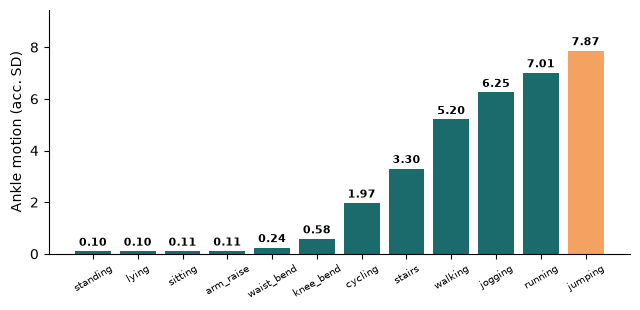

In [9]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30)
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

fig1 = con.execute("""SELECT activity AS g, AVG(ankle_accmag_std) AS v FROM har GROUP BY 1 ORDER BY 2""").df()
bar_chart(fig1.g, fig1.v, 'Ankle motion (acc. SD)', 'report/fig_rq1.png', highlight=int(fig1.v.idxmax()), fmt='{:.2f}')

## Bàn giao và test case

- **Làm gì:** ghi `manifest.json` (số dòng, số cột, mã băm) và chạy các kiểm tra tự động.
- **Vì sao:** Notebook B đọc manifest trước khi chạy, nên hai người làm song song mà không lệch dữ liệu.
- **Kiểm tra:** mọi `assert` qua. Sinh viên B chạy lại notebook này trên máy mình và ghi vào ô Đối chứng.

In [10]:
import json, hashlib
path = 'data/processed/mhealth.parquet'; t = pd.read_parquet(path)
feat_n = con.execute('SELECT COUNT(*) FROM feat').fetchone()[0]
with open(path, 'rb') as f: md5 = hashlib.md5(f.read()).hexdigest()
manifest = {'file': path, 'rows': len(t), 'columns': t.shape[1], 'feat_rows': feat_n, 'md5': md5}
with open('data/processed/manifest.json', 'w', encoding='utf-8') as f: json.dump(manifest, f, indent=2)
print(manifest)
assert not t.duplicated(['subject', 'run', 'win']).any(), 'duplicated windows'
assert feat_n == len(t), 'feat table lost rows'
assert feat_n > 0 and os.path.exists('sql/queries.sql') and os.path.exists('report/table_cleaning_log.csv')
print('Notebook A: all checks passed')

{'file': 'data/processed/mhealth.parquet', 'rows': 33148, 'columns': 45, 'feat_rows': 33148, 'md5': '3d81b90d136d90450e7650e80612e8e9'}
Notebook A: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Số dòng | md5 khớp | Ghi chú |
|---|---|---|---|---|
| | | | | |

### Báo cáo tiến độ (dán vào kênh nhóm trước 12:00 ngày báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: